# Fase 6 - Entrega 2: Comparação de abordagens de Visão Computacional

**FarmTech Solutions** - comparação entre YOLO adaptada, YOLO padrão e CNN treinada do zero

## 1. Introdução

Na Entrega 1, o YOLOv5 foi customizado para detectar **vacas** e **tratores** a partir de um dataset próprio. Nesta entrega, o mesmo dataset é usado para comparar essa solução com duas abordagens "concorrentes":

| Abordagem | Descrição | Tipo de tarefa |
|---|---|---|
| **YOLO adaptada** | YOLOv5s treinado com o dataset da Entrega 1 (60 épocas) | Detecção (classe + localização) |
| **YOLO padrão** | YOLOv5s pré-treinado no dataset COCO, sem nenhum treino adicional | Detecção (classe + localização) |
| **CNN do zero** | Rede convolucional simples, treinada apenas com as imagens do projeto | Classificação (apenas a classe) |

As três abordagens são avaliadas nos mesmos critérios:

1. Facilidade de uso e integração
2. Precisão do modelo
3. Tempo de treinamento ou customização
4. Tempo de inferência (predição)

### Como a precisão é comparada

A CNN apenas **classifica** a imagem inteira, enquanto as YOLOs **detectam** objetos. Para comparar as três na mesma base, a métrica principal é a **acurácia por imagem** nas 8 imagens de teste (4 vacas e 4 tratores), que nenhum modelo viu durante o treinamento:

- **CNN:** a classe prevista é a saída da rede
- **YOLOs:** a classe prevista é a da detecção com maior confiança na imagem; se nada for detectado, a predição é considerada errada

Como o conjunto de teste é pequeno, cada imagem representa 12,5% da acurácia, e os resultados devem ser interpretados com cautela.

## 2. Preparação do ambiente

O notebook deve ser executado no Google Colab com GPU (*Ambiente de execução > Alterar tipo de ambiente de execução > GPU*). Os pesos da YOLO adaptada são lidos da pasta `resultados`, gerada no Drive ao final do notebook da Entrega 1.

In [1]:
# bibliotecas utilizadas
import os
import glob
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# montagem do Google Drive no Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# pasta do projeto no Drive, classes e pesos da YOLO treinada na Entrega 1
BASE = '/content/drive/MyDrive/FIAP/FASE6_CAP1'
CLASSES = ['vaca', 'trator']
PESOS_YOLO = os.path.join(BASE, 'resultados', 'train', 'treino_60ep', 'weights', 'best.pt')

print('Pasta existe?', os.path.exists(BASE))
print('Pesos da Entrega 1 encontrados?', os.path.exists(PESOS_YOLO))

Pasta existe? True
Pesos da Entrega 1 encontrados? True


In [4]:
# imagens de teste com a classe real (definida pela pasta)
teste = []
for classe in CLASSES:
    for arq in sorted(glob.glob(os.path.join(BASE, 'teste', classe, '*.jpg'))):
        teste.append((arq, classe))

# imagens carregadas na memoria antes das predicoes, para que o tempo medido
# seja apenas o da inferencia (sem o tempo de leitura dos arquivos no Drive)
imagens = {arq: Image.open(arq).convert('RGB') for arq, _ in teste}

print('Imagens de teste:', len(teste))

Imagens de teste: 8


## 3. Instalação do YOLOv5

As duas abordagens com YOLO usam o mesmo repositório do YOLOv5. Os modelos são carregados com o `torch.hub`, que permite fazer a predição direto no Python, sem chamar o `detect.py`. Isso facilita medir o tempo de inferência de cada imagem.

Para que a comparação de tempo seja justa, as imagens de teste são carregadas na memória antes das predições, e a primeira predição de cada modelo é descartada (aquecimento da GPU). Assim, o tempo medido corresponde apenas à inferência, sem a leitura dos arquivos no Drive.

In [5]:
# repositorio e dependencias do YOLOv5
if not os.path.exists('/content/yolov5'):
    !git clone https://github.com/ultralytics/yolov5 /content/yolov5
!pip install -r /content/yolov5/requirements.txt -q

Cloning into '/content/yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (199/199), done.
remote: Total 18770 (delta 264), reused 128 (delta 128), pack-reused 18443 (from 5)
Receiving objects: 100% (18770/18770), 17.83 MiB | 17.32 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.8 MB/s eta 0:00:00


In [6]:
# carregamento dos dois modelos YOLO (confianca minima de 25%, igual a Entrega 1)
import torch

modelo_adaptado = torch.hub.load('/content/yolov5', 'custom', path=PESOS_YOLO, source='local')
modelo_padrao = torch.hub.load('/content/yolov5', 'yolov5s', source='local')

modelo_adaptado.conf = 0.25
modelo_padrao.conf = 0.25

print('GPU disponivel?', torch.cuda.is_available())
print('Classes da YOLO adaptada:', list(modelo_adaptado.names.values()))
print('Quantidade de classes da YOLO padrao (COCO):', len(modelo_padrao.names))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)



100%|██████████| 14.1M/14.1M [00:00<00:00, 133MB/s]


Fusing layers... 


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
GPU disponivel? True
Classes da YOLO adaptada: ['vaca', 'trator']
Quantidade de classes da YOLO padrao (COCO): 80


In [7]:
# avalia um modelo YOLO nas imagens de teste
# mapa: converte o nome da classe do modelo para 'vaca' ou 'trator'
def avaliar_yolo(modelo, mapa):
    modelo(imagens[teste[0][0]])  # primeira predicao descartada (aquecimento da GPU)
    linhas = []
    for arq, classe_real in teste:
        inicio = time.time()
        resultado = modelo(imagens[arq])
        tempo_ms = (time.time() - inicio) * 1000

        deteccoes = resultado.pandas().xyxy[0]
        validas = deteccoes[deteccoes['name'].isin(mapa.keys())]

        if len(validas) > 0:
            melhor = validas.sort_values('confidence', ascending=False).iloc[0]
            prevista = mapa[melhor['name']]
            confianca = melhor['confidence']
        else:
            prevista = 'nada detectado'
            confianca = 0.0

        todas = ', '.join(f"{n} ({c:.2f})" for n, c in zip(deteccoes['name'], deteccoes['confidence']))
        linhas.append({
            'arquivo': os.path.basename(arq),
            'classe_real': classe_real,
            'classe_prevista': prevista,
            'confianca': round(confianca, 2),
            'acertou': prevista == classe_real,
            'tempo_ms': round(tempo_ms, 1),
            'todas_deteccoes': todas if todas else '-',
        })
    return pd.DataFrame(linhas)


# mostra as imagens de teste com as caixas desenhadas pelo modelo
def mostrar_deteccoes(modelo, titulo):
    fig, eixos = plt.subplots(2, 4, figsize=(18, 9))
    for eixo, (arq, classe) in zip(eixos.flatten(), teste):
        resultado = modelo(imagens[arq])
        eixo.imshow(resultado.render()[0])
        eixo.set_title(os.path.basename(arq), fontsize=9)
        eixo.axis('off')
    fig.suptitle(titulo, fontsize=16)
    plt.tight_layout()
    plt.show()

## 4. Abordagem 1: YOLO adaptada (Entrega 1)

Modelo `yolov5s` treinado na Entrega 1 com as 64 imagens rotuladas no Make Sense, durante 60 épocas. Ele conhece apenas as duas classes do projeto: `vaca` e `trator`.

O custo de customização dessa abordagem envolveu montar o dataset, **rotular manualmente 72 imagens** com caixas delimitadoras e treinar o modelo por **4,1 minutos** na GPU T4 (tempo medido na Entrega 1).

In [8]:
# avaliacao da YOLO adaptada
res_adaptada = avaliar_yolo(modelo_adaptado, {'vaca': 'vaca', 'trator': 'trator'})
print(f"Acuracia no teste: {res_adaptada['acertou'].mean():.1%}")
res_adaptada

Acuracia no teste: 100.0%


,arquivo,classe_real,classe_prevista,confianca,acertou,tempo_ms,todas_deteccoes
0,vaca_01_teste.jpg,vaca,vaca,0.84,True,22.9,vaca (0.84)
1,vaca_02_teste.jpg,vaca,vaca,0.70,True,21.1,vaca (0.70)
2,vaca_03_teste.jpg,vaca,vaca,0.75,True,20.2,vaca (0.75)
3,vaca_04_teste.jpg,vaca,vaca,0.47,True,20.2,vaca (0.47)
4,trator_01_teste.jpg,trator,trator,0.80,True,51.5,trator (0.80)
5,trator_02_teste.jpg,trator,trator,0.55,True,19.9,trator (0.55)
6,trator_03_teste.jpg,trator,trator,0.63,True,52.6,trator (0.63)
7,trator_04_teste.jpg,trator,trator,0.65,True,20.4,trator (0.65)


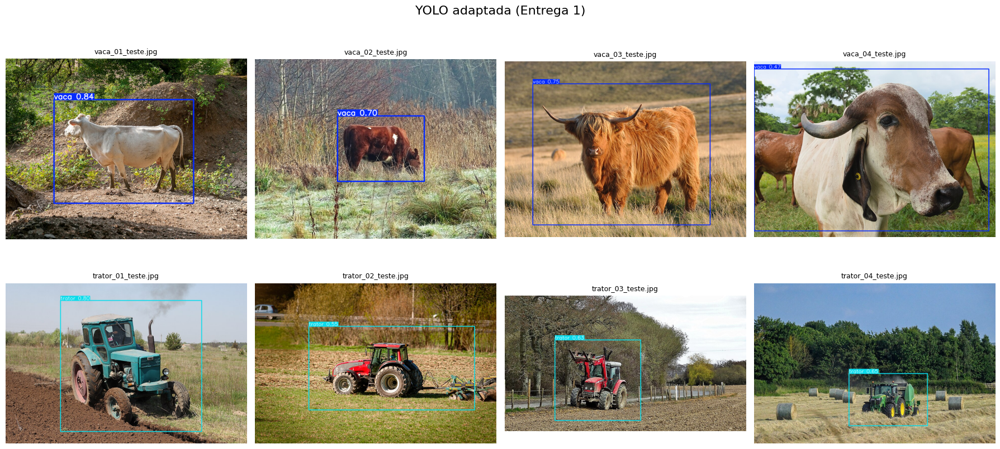

In [9]:
mostrar_deteccoes(modelo_adaptado, 'YOLO adaptada (Entrega 1)')

## 5. Abordagem 2: YOLO padrão (pré-treinada no COCO)

Modelo `yolov5s` original, treinado pelos autores do YOLOv5 no dataset **COCO**, que tem 80 classes de objetos do dia a dia. Nenhum treino adicional é feito: o modelo é usado exatamente como vem.

Ponto importante: o COCO tem a classe **`cow`** (vaca), mas **não tem uma classe para trator**. Para não descartar a abordagem logo de início, as classes de veículo mais próximas foram consideradas como "trator" na avaliação: **`truck`** (caminhão), **`car`** (carro) e **`bus`** (ônibus). Mesmo assim, o modelo não "sabe" o que é um trator, e isso já é uma limitação importante para o cenário da FarmTech.

In [10]:
# avaliacao da YOLO padrao (classes do COCO convertidas para as classes do projeto)
mapa_coco = {'cow': 'vaca', 'truck': 'trator', 'car': 'trator', 'bus': 'trator'}
res_padrao = avaliar_yolo(modelo_padrao, mapa_coco)
print(f"Acuracia no teste: {res_padrao['acertou'].mean():.1%}")
res_padrao

Acuracia no teste: 100.0%


,arquivo,classe_real,classe_prevista,confianca,acertou,tempo_ms,todas_deteccoes
0,vaca_01_teste.jpg,vaca,vaca,0.90,True,71.5,cow (0.90)
1,vaca_02_teste.jpg,vaca,vaca,0.90,True,75.3,cow (0.90)
2,vaca_03_teste.jpg,vaca,vaca,0.92,True,59.7,cow (0.92)
3,vaca_04_teste.jpg,vaca,vaca,0.73,True,55.6,"cow (0.73), cow (0.72), cow (0.36)"
4,trator_01_teste.jpg,trator,trator,0.83,True,22.0,truck (0.83)
5,trator_02_teste.jpg,trator,trator,0.68,True,20.0,"car (0.68), truck (0.42)"
6,trator_03_teste.jpg,trator,trator,0.86,True,26.0,truck (0.86)
7,trator_04_teste.jpg,trator,trator,0.70,True,19.8,truck (0.70)


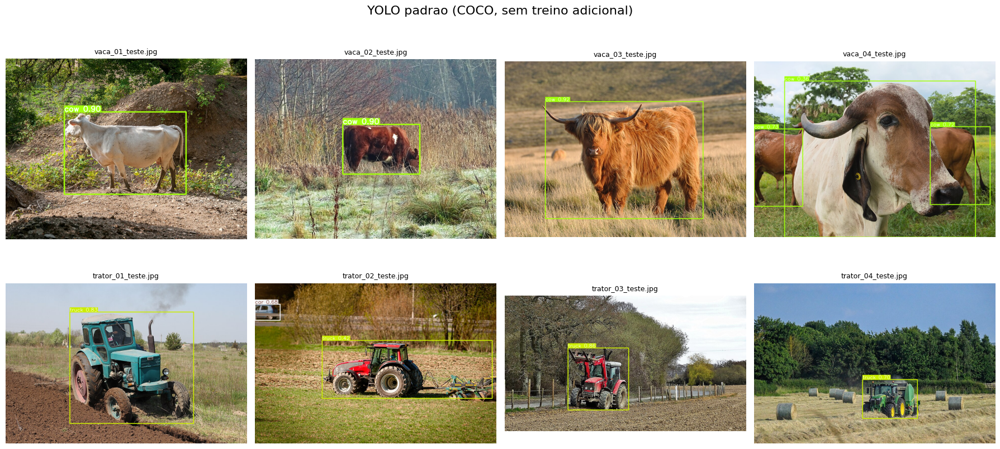

In [11]:
mostrar_deteccoes(modelo_padrao, 'YOLO padrao (COCO, sem treino adicional)')

## 6. Abordagem 3: CNN treinada do zero

Uma rede neural convolucional (CNN) simples, construída com o Keras e treinada **somente** com as imagens do projeto, sem nenhum conhecimento prévio. Diferente das YOLOs, a CNN não localiza o objeto: ela apenas diz se a imagem é de uma **vaca** ou de um **trator**. Por isso, não precisa de caixas delimitadoras, só das imagens separadas em pastas por classe.

Arquitetura utilizada:

- Imagens redimensionadas para 128 x 128 pixels e valores normalizados entre 0 e 1
- *Data augmentation* (espelhamento, rotação e zoom aleatórios), para gerar variações das poucas imagens de treino e reduzir o overfitting
- 3 blocos de convolução + max pooling (16, 32 e 64 filtros)
- Camada densa com 64 neurônios e *dropout* de 50%
- Saída com 1 neurônio sigmoide (probabilidade de ser trator)

O treino usa 64 imagens (32 de cada classe), 40 épocas e as 8 imagens de validação para acompanhar o desempenho.

In [12]:
# carregamento das imagens a partir das pastas (a pasta define a classe: 0 = vaca, 1 = trator)
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
TAMANHO = (128, 128)

def carregar(etapa, embaralhar):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(BASE, etapa), class_names=CLASSES, label_mode='binary',
        image_size=TAMANHO, batch_size=8, shuffle=embaralhar, seed=42)

treino_cnn = carregar('treino', True)
val_cnn = carregar('validacao', False)

Found 64 files belonging to 2 classes.
Found 8 files belonging to 2 classes.


In [13]:
# arquitetura da CNN
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=TAMANHO + (3,)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,529 (3.15 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# treinamento da CNN com medicao de tempo
inicio = time.time()
historico = cnn.fit(treino_cnn, validation_data=val_cnn, epochs=40, verbose=2)
tempo_cnn = time.time() - inicio
print(f'Tempo de treino da CNN: {tempo_cnn/60:.1f} minutos')

Epoch 1/40
8/8 - 23s - 3s/step - accuracy: 0.4688 - loss: 0.7848 - val_accuracy: 0.5000 - val_loss: 0.6862
Epoch 2/40
8/8 - 0s - 54ms/step - accuracy: 0.4375 - loss: 0.7087 - val_accuracy: 0.5000 - val_loss: 0.6953
Epoch 3/40
8/8 - 1s - 79ms/step - accuracy: 0.5000 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6927
Epoch 4/40
8/8 - 1s - 75ms/step - accuracy: 0.5312 - loss: 0.6891 - val_accuracy: 0.5000 - val_loss: 0.6841
Epoch 5/40
8/8 - 0s - 57ms/step - accuracy: 0.5625 - loss: 0.6879 - val_accuracy: 0.6250 - val_loss: 0.6770
Epoch 6/40
8/8 - 0s - 54ms/step - accuracy: 0.5938 - loss: 0.6852 - val_accuracy: 0.6250 - val_loss: 0.6613
Epoch 7/40
8/8 - 0s - 56ms/step - accuracy: 0.7812 - loss: 0.6451 - val_accuracy: 0.5000 - val_loss: 0.7042
Epoch 8/40
8/8 - 0s - 53ms/step - accuracy: 0.6250 - loss: 0.6629 - val_accuracy: 0.5000 - val_loss: 0.8445
Epoch 9/40
8/8 - 0s - 55ms/step - accuracy: 0.6406 - loss: 0.6932 - val_accuracy: 0.6250 - val_loss: 0.6096
Epoch 10/40
8/8 - 1s - 63ms/s

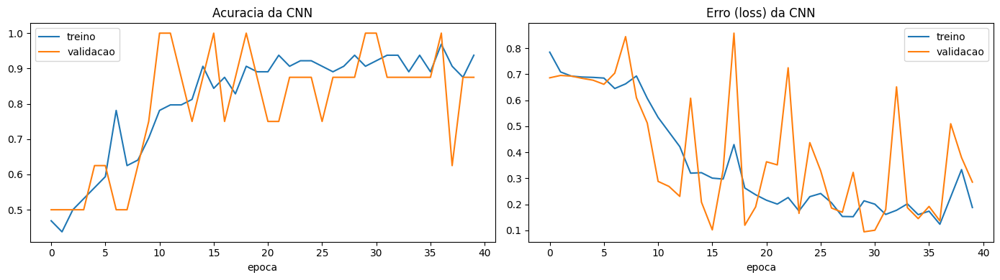

In [15]:
# curvas de acuracia e erro ao longo das epocas
h = pd.DataFrame(historico.history)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))

eixos[0].plot(h['accuracy'], label='treino')
eixos[0].plot(h['val_accuracy'], label='validacao')
eixos[0].set_title('Acuracia da CNN')
eixos[0].set_xlabel('epoca')
eixos[0].legend()

eixos[1].plot(h['loss'], label='treino')
eixos[1].plot(h['val_loss'], label='validacao')
eixos[1].set_title('Erro (loss) da CNN')
eixos[1].set_xlabel('epoca')
eixos[1].legend()

plt.tight_layout()
plt.show()

In [16]:
# avaliacao da CNN nas imagens de teste, uma imagem por vez para medir o tempo
# (mesmo redimensionamento usado pelo image_dataset_from_directory no treino)
def preparar(arq):
    img = tf.io.decode_image(tf.io.read_file(arq), channels=3, expand_animations=False)
    return tf.expand_dims(tf.image.resize(img, TAMANHO, method='bilinear'), 0)

cnn.predict(preparar(teste[0][0]), verbose=0)  # aquecimento

linhas = []
for arq, classe_real in teste:
    entrada = preparar(arq)
    inicio = time.time()
    prob_trator = float(cnn.predict(entrada, verbose=0)[0][0])
    tempo_ms = (time.time() - inicio) * 1000

    prevista = 'trator' if prob_trator >= 0.5 else 'vaca'
    linhas.append({
        'arquivo': os.path.basename(arq),
        'classe_real': classe_real,
        'classe_prevista': prevista,
        'confianca': round(prob_trator if prevista == 'trator' else 1 - prob_trator, 2),
        'acertou': prevista == classe_real,
        'tempo_ms': round(tempo_ms, 1),
    })

res_cnn = pd.DataFrame(linhas)
print(f"Acuracia no teste: {res_cnn['acertou'].mean():.1%}")
res_cnn

Acuracia no teste: 75.0%


,arquivo,classe_real,classe_prevista,confianca,acertou,tempo_ms
0,vaca_01_teste.jpg,vaca,vaca,0.62,True,69.4
1,vaca_02_teste.jpg,vaca,trator,0.80,False,68.3
2,vaca_03_teste.jpg,vaca,trator,0.98,False,70.7
3,vaca_04_teste.jpg,vaca,vaca,0.86,True,107.3
4,trator_01_teste.jpg,trator,trator,1.00,True,72.7
5,trator_02_teste.jpg,trator,trator,1.00,True,77.6
6,trator_03_teste.jpg,trator,trator,1.00,True,68.2
7,trator_04_teste.jpg,trator,trator,1.00,True,69.0


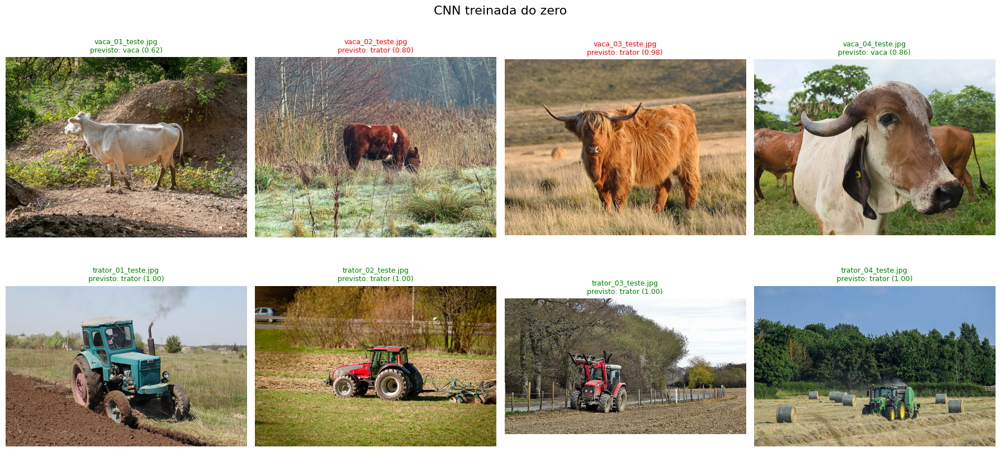

In [17]:
# imagens de teste com a classe prevista pela CNN (verde = acerto, vermelho = erro)
fig, eixos = plt.subplots(2, 4, figsize=(18, 9))
for eixo, (arq, _), (_, linha) in zip(eixos.flatten(), teste, res_cnn.iterrows()):
    eixo.imshow(Image.open(arq))
    cor = 'green' if linha['acertou'] else 'red'
    eixo.set_title(f"{linha['arquivo']}\nprevisto: {linha['classe_prevista']} ({linha['confianca']:.2f})", fontsize=9, color=cor)
    eixo.axis('off')
fig.suptitle('CNN treinada do zero', fontsize=16)
plt.tight_layout()
plt.show()

## 7. Comparação entre as abordagens

As tabelas abaixo reúnem os resultados das três abordagens nas mesmas 8 imagens de teste.

In [18]:
# resultado de cada abordagem imagem a imagem
por_imagem = pd.DataFrame({
    'arquivo': res_adaptada['arquivo'],
    'classe_real': res_adaptada['classe_real'],
    'YOLO adaptada': res_adaptada['classe_prevista'],
    'YOLO padrao': res_padrao['classe_prevista'],
    'CNN': res_cnn['classe_prevista'],
})
por_imagem

,arquivo,classe_real,YOLO adaptada,YOLO padrao,CNN
0,vaca_01_teste.jpg,vaca,vaca,vaca,vaca
1,vaca_02_teste.jpg,vaca,vaca,vaca,trator
2,vaca_03_teste.jpg,vaca,vaca,vaca,trator
3,vaca_04_teste.jpg,vaca,vaca,vaca,vaca
4,trator_01_teste.jpg,trator,trator,trator,trator
5,trator_02_teste.jpg,trator,trator,trator,trator
6,trator_03_teste.jpg,trator,trator,trator,trator
7,trator_04_teste.jpg,trator,trator,trator,trator


In [19]:
# tabela resumo dos criterios de comparacao
resumo = pd.DataFrame({
    'Acuracia no teste': [res_adaptada['acertou'].mean(), res_padrao['acertou'].mean(), res_cnn['acertou'].mean()],
    'Tempo de treino (min)': [4.1, 0.0, tempo_cnn / 60],
    'Inferencia media (ms/imagem)': [res_adaptada['tempo_ms'].mean(), res_padrao['tempo_ms'].mean(), res_cnn['tempo_ms'].mean()],
    'Parametros (milhoes)': [
        sum(p.numel() for p in modelo_adaptado.parameters()) / 1e6,
        sum(p.numel() for p in modelo_padrao.parameters()) / 1e6,
        cnn.count_params() / 1e6,
    ],
    'Precisa rotular caixas?': ['sim', 'nao', 'nao'],
    'Localiza o objeto?': ['sim', 'sim', 'nao'],
    'Reconhece trator?': ['sim', 'nao (so classes do COCO)', 'sim'],
}, index=['YOLO adaptada', 'YOLO padrao', 'CNN do zero'])

resumo.round(3)

,Acuracia no teste,Tempo de treino (min),Inferencia media (ms/imagem),Parametros (milhoes),Precisa rotular caixas?,Localiza o objeto?,Reconhece trator?
YOLO adaptada,1.00,4.100,28.600,7.016,sim,sim,sim
YOLO padrao,1.00,0.000,43.738,7.226,nao,sim,nao (so classes do COCO)
CNN do zero,0.75,0.714,75.400,0.827,nao,nao,sim


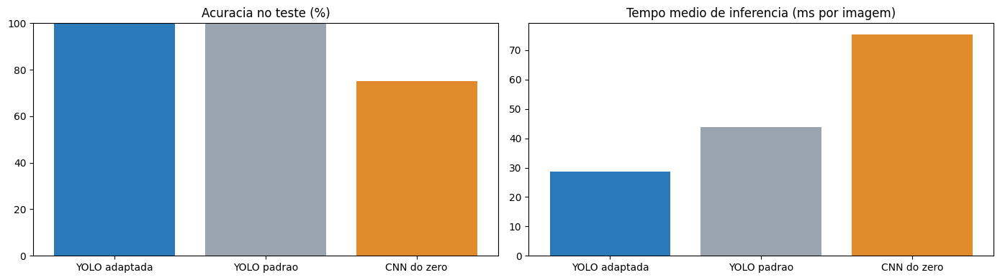

In [20]:
# graficos de acuracia e tempo de inferencia
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
nomes = resumo.index

eixos[0].bar(nomes, resumo['Acuracia no teste'] * 100, color=['#2a7ab9', '#9aa5b1', '#e08a2c'])
eixos[0].set_title('Acuracia no teste (%)')
eixos[0].set_ylim(0, 100)

eixos[1].bar(nomes, resumo['Inferencia media (ms/imagem)'], color=['#2a7ab9', '#9aa5b1', '#e08a2c'])
eixos[1].set_title('Tempo medio de inferencia (ms por imagem)')

plt.tight_layout()
plt.show()

## 8. Análise crítica e conclusões

### Resumo dos resultados

| Critério | YOLO adaptada | YOLO padrão (COCO) | CNN do zero |
|---|---|---|---|
| Acurácia no teste (8 imagens) | 100% (8/8) | 100% (8/8)* | 75% (6/8) |
| Confiança média nos acertos | 0,67 | 0,82 | 0,91 |
| Tempo de treino ou customização | 4,1 min + rotulação de 72 imagens | nenhum | 0,7 min |
| Inferência média (GPU T4) | 28,6 ms | 43,7 ms | 75,4 ms |
| Parâmetros | 7,0 milhões | 7,2 milhões | 0,8 milhão |
| Localiza o objeto na imagem? | sim | sim | não |

\* Considerando `truck` e `car` como trator, já que o COCO não tem essa classe.

### Facilidade de uso e integração

A **YOLO padrão** é a mais simples: bastam duas linhas de código para carregar o modelo e fazer predições, sem dataset, sem rotulação e sem treino. A **YOLO adaptada** usa exatamente a mesma forma de integração (`torch.hub`), mas exige todo o trabalho prévio da Entrega 1: coleta das imagens, rotulação manual de 72 imagens no Make Sense e treinamento. A **CNN do zero** não precisa de caixas delimitadoras, só das imagens separadas em pastas por classe, mas exige definir a arquitetura da rede, escolher hiperparâmetros e escrever o código de treino e avaliação, o que demanda mais conhecimento técnico.

### Precisão do modelo

As duas YOLOs acertaram as 8 imagens de teste, mas por motivos diferentes:

- A **YOLO adaptada** reconhece `vaca` e `trator` como classes próprias, exatamente as do problema. As confianças foram mais baixas (0,47 a 0,84), o que é esperado para um modelo treinado com apenas 64 imagens.
- A **YOLO padrão** teve confianças mais altas para as vacas (0,73 a 0,92) e foi a única que encontrou as três vacas de `vaca_04`. Isso se explica pelo COCO, que tem milhares de imagens de vacas. Porém, ela **não reconhece tratores**: classificou-os como `truck` (caminhão) ou `car` (carro). O acerto de 100% só existe porque essas classes foram aceitas como "trator". Em uma fazenda com caminhões e carros, o modelo não teria como diferenciá-los de um trator.
- A **CNN do zero** acertou os 4 tratores, mas errou 2 das 4 vacas (`vaca_02` e `vaca_03`), classificando-as como trator com confiança alta (0,80 e 0,98). Durante o treino, a acurácia de validação oscilou entre 62,5% e 100% de uma época para outra, sinal de que o modelo é instável. Com apenas 64 imagens e nenhum conhecimento prévio, a rede não consegue aprender características gerais o suficiente. A confiança média alta (0,91) não indica qualidade, já que os erros também tiveram confiança alta.

### Tempo de treinamento ou customização

A **YOLO padrão** não tem custo de treinamento. A **CNN** treinou em apenas 0,7 minuto, por ser uma rede pequena com 128 x 128 pixels de entrada. A **YOLO adaptada** levou 4,1 minutos de treino, mas o maior custo foi o trabalho manual de rotulação das caixas, que é a etapa mais demorada da abordagem.

### Tempo de inferência

As duas YOLOs têm a mesma arquitetura (`yolov5s`), então o esperado é que tenham tempos equivalentes. A YOLO adaptada ficou em torno de 20 ms em 6 das 8 imagens. A YOLO padrão também ficou em torno de 20 ms nos tratores, mas entre 55 e 75 ms nas vacas. Como o modelo é o mesmo, essa diferença entre as médias (28,6 ms e 43,7 ms) provavelmente vem da variação da GPU compartilhada do Colab, e não de uma diferença real de desempenho. A **CNN** teve a maior média (75,4 ms), mesmo com cerca de 8 vezes menos parâmetros. Isso acontece porque o `model.predict` do Keras tem um custo fixo alto ao processar uma imagem por vez. O valor reflete esse custo e não a complexidade da rede. Na prática, as três abordagens são rápidas o suficiente para aplicações em tempo real, como monitoramento por câmeras.

### Qual abordagem é a mais indicada para a FarmTech?

Para o cenário do projeto, a **YOLO adaptada** é a melhor escolha. Ela é a única que reconhece trator como uma classe própria, localiza o objeto na imagem, acertou todas as imagens de teste e tem inferência rápida. O custo de rotulação é pago uma única vez.

A **YOLO padrão** é uma boa opção quando os objetos de interesse já existem no COCO (como vacas, cavalos, pessoas e carros), pois funciona sem nenhum treino. Uma estratégia possível seria usá-la como ponto de partida e customizar apenas as classes que o COCO não conhece, como foi feito na Entrega 1.

A **CNN do zero** só faria sentido se fosse necessário apenas classificar a imagem inteira, sem localizar objetos, e com um dataset bem maior. Com poucas imagens, aproveitar um modelo pré-treinado é muito mais eficiente do que treinar uma rede do zero.

### Limitações da comparação

- O teste tem apenas 8 imagens: cada erro representa 12,5% da acurácia
- A acurácia por imagem não avalia a qualidade das caixas, então YOLO e CNN são comparadas apenas na classificação
- As imagens de teste têm um objeto principal bem visível, o que facilita a tarefa
- O resultado da CNN varia entre execuções, por causa da inicialização aleatória dos pesos e do treino na GPU
- O mapeamento `truck`/`car` para trator favorece a YOLO padrão e não seria válido em um cenário real
- Os tempos de inferência foram medidos em uma GPU compartilhada do Colab, sujeita a variações